# Stability, Systems of ODEs, and Stiff Problems

## 1. Stability of Numerical Methods for Solving the Cauchy Problem

In the previous lectures we examined how errors in the initial data and the right-hand side propagate over a finite interval. We now distinguish stability as the step tends to zero from stability over many steps at a fixed step size. Recall the difference scheme

$$
\frac1h\sum_{j=0}^k\alpha_j y_{n+1-j}=\Phi(t_n,y_{n+1-k},\ldots,y_{n+1},h).\tag{1}
$$

Here $k\geq1$, $\alpha_0\ne0$, the coefficients $\alpha_j$ are fixed, and $h=(T-t_0)/N$ on a uniform grid. We compare solutions $y_n$ and $y_n^*$ of (1) which start from $y_0,\ldots,y_{k-1}$ and $y_0^*,\ldots,y_{k-1}^*$. Suppose each step is well defined and locally Lipschitz in the previous values on the part of state space under consideration. Then, for fixed $T$ and $h$, sufficiently small starting errors $\varepsilon_i=y_i-y_i^*$ satisfy a bound of the form

$$
\max_{0\leq n\leq N}|y_n-y_n^*|\leq K^h(T)\max_{0\leq i<k}|\varepsilon_i|.\tag{2}
$$

The factor $K^h(T)$ measures the sensitivity to starting errors and may depend on both $h$ and $T$.

### 1.1. Zero-Stability

The continuous stability estimate on a finite interval allows the error amplification factor to depend on $T$ (see Lecture 06.1). For the discrete problem, a bound that grows without limit as $h\to0$ gives no uniform control under refinement. A basic test is to require, for the equation $y'=0$ and all sufficiently small $h$, the estimate

$$
\max_{0\leq n\leq N}|y_n-y_n^*|\leq\widetilde K(T)\max_{0\leq i<k}|\varepsilon_i|.\tag{3}
$$

**Definition 1 (zero-stability).** A method is *zero-stable* if (3) holds for the test equation $y'=0$ with $\widetilde K(T)$ independent of $h$ and of the starting data. We assume the right-hand side of (1) vanishes on this test equation. This is the case for the Runge–Kutta and Adams methods considered here.

On this test equation the update reduces to a homogeneous linear recurrence with constant coefficients

$$
\alpha_0 y_{n+1}+\alpha_1 y_n+\cdots+\alpha_k y_{n+1-k}=0.\tag{4}
$$

By linearity the error $\varepsilon_n=y_n-y_n^*$ satisfies the same recurrence

$$
\alpha_0\varepsilon_{n+1}+\alpha_1\varepsilon_n+\cdots+\alpha_k\varepsilon_{n+1-k}=0.\tag{5}
$$

**Definition 2 (characteristic polynomial).** Substituting $\varepsilon_n=q^n$ into (5) and dividing by $q^{n+1-k}$ for $q\ne0$ gives the characteristic equation

$$
P(q)=\alpha_0 q^k+\alpha_1 q^{k-1}+\cdots+\alpha_k=0.\tag{6}
$$

The polynomial $P$ is the *characteristic polynomial*. If trailing coefficients vanish, the recurrence has shorter memory. The corresponding zero roots of $P$ represent transient starting-data modes.

For a nonzero root $q$ of multiplicity $m$, the corresponding modes are $q^n,nq^n,\ldots,n^{m-1}q^n$. If all roots are nonzero, let $q_1,\ldots,q_r$ be the distinct roots with multiplicities $m_i$. The general solution of (5) is

$$
\varepsilon_n=\sum_{i=1}^r\sum_{\ell=0}^{m_i-1}c_{i\ell} n^\ell q_i^n.\tag{7}
$$

For distinct nonzero roots this simplifies to

$$
\varepsilon_n=c_1 q_1^n+\cdots+c_k q_k^n.\tag{8}
$$

If there are zero roots, these representations apply to the shorter recurrence after the finite starting transient. Equivalently, one can keep the $k$-dimensional companion matrix, for which the zero eigenvalue has nilpotent Jordan blocks.

**Definition 3 (root condition).** Every root of $P$ must satisfy $|q_i|\leq1$, and every root with $|q_i|=1$ must be simple. For a consistent scheme, exactness on constants gives $\sum_{j=0}^k\alpha_j=0$, so $q=1$ is a root.

**Theorem 1 (root criterion for zero-stability).** A fixed-coefficient method of the form (1) whose right-hand side vanishes on $y'=0$ is zero-stable if and only if its characteristic polynomial satisfies the root condition.

**Proof.** If $|q|>1$, choose the starting errors from the mode $q^n$. If a unit-modulus root is repeated, choose them from $nq^n$. Either mode can be scaled to have arbitrarily small starting errors and grows without bound as $N=(T-t_0)/h\to\infty$. For real coefficients a bound on all real starting vectors would also bound the real and imaginary parts of any complex mode. Thus (3) requires the root condition.

Conversely, the recurrence advances the vector of the most recent $k$ errors by a fixed companion matrix. In its Jordan form, blocks for $|q|<1$ have bounded powers, including nilpotent blocks for $q=0$. Blocks for $|q|=1$ are scalar and also have bounded powers. The fixed change of basis therefore gives a bound independent of the number of steps and hence of $h$. $\square$

**Theorem 2 (zero-stability of Runge–Kutta and Adams methods).** Runge–Kutta and Adams methods are zero-stable.

**Proof.** Runge–Kutta reduces to $y_{n+1}-y_n=0$ on $y'=0$, with the simple characteristic root $q=1$. A $k$-step Adams method reduces to

$$
y_{n+1}-y_n+\sum_{j=2}^k0\cdot y_{n+1-j}=0.\tag{9}
$$

Its characteristic polynomial is $q^{k-1}(q-1)$, with a simple root at $1$ and, for $k>1$, a root at $0$ of multiplicity $k-1$. The formula for the polynomial also applies when $k=1$. Theorem 1 applies in both cases. $\square$

### 1.2. Absolute Stability

Zero-stability controls starting errors in the zero test as $h\to0$ on a fixed interval. For long integrations at a fixed $h$, consider the model problem

$$
y'=\lambda y,\quad y(t_0)=y_0.\tag{10}
$$

The exact perturbation is proportional to $e^{\lambda(t-t_0)}$. It is bounded for $\operatorname{Re}\lambda\leq0$ and decays for $\operatorname{Re}\lambda<0$. On (10), linear multistep methods and Runge–Kutta methods give a constant-coefficient recurrence. Write it as

$$
\frac1h\sum_{j=0}^k\alpha_j y_{n+1-j}=\lambda\sum_{j=0}^k\beta_j(z)y_{n+1-j},\quad z=h\lambda.\tag{11}
$$

The $\beta_j$ are constants for linear multistep methods. For Runge–Kutta, the step is $y_{n+1}=R(z)y_n$ wherever the stages are uniquely solvable. We assume the recurrence determines $y_{n+1}$ uniquely. The error then satisfies

$$
\frac1h\sum_{j=0}^k\alpha_j\varepsilon_{n+1-j}=\lambda\sum_{j=0}^k\beta_j(z)\varepsilon_{n+1-j},\tag{12}
$$

or, in homogeneous form,

$$
\sum_{j=0}^k\gamma_j(z)\varepsilon_{n+1-j}=0,\quad \gamma_j(z)=\alpha_j-z\beta_j(z),\quad\gamma_0(z)\ne0.\tag{13}
$$

**Definition 4 (absolute stability).** At a fixed $z=h\lambda$ for which the step is well defined, the method is *absolutely stable* in the bounded-error sense if the polynomial

$$
P(q,z)=\sum_{j=0}^k\gamma_j(z)q^{k-j}\tag{14}
$$

satisfies the root condition. The set $D$ of such points $z$ is the *region of absolute stability*. This convention includes simple unit-modulus roots, for which a perturbation can persist. For decay of every perturbation all roots must have modulus strictly less than one. For a one-step method the two tests reduce to $|R(z)|\leq1$ and $|R(z)|<1$, respectively.

**Example 1 (negative real $\lambda$).** Explicit Euler has $R(z)=1+z$. For $\lambda<0$, its absolute stability condition is equivalent to

$$
h\leq h_0=\frac{2}{|\lambda|}.\tag{15}
$$

The Euler–Cauchy and improved Euler methods both have $R(z)=1+z+z^2/2$. On the negative real axis, $|R(z)|\leq1$ likewise gives $-2\leq z\leq0$. For classical RK4, $R(z)=1+z+z^2/2+z^3/6+z^4/24$. Setting $r=-z>0$ and solving $R(-r)=1$ gives

$$
h\leq\frac{r_*}{|\lambda|},\quad r_*^3-4r_*^2+12r_*-24=0,\quad r_*\approx2.785293563.\tag{16}
$$

The cubic is strictly increasing, so its positive root is unique. Also, $24R(-r)=(r^2-2r)^2+8(r-\tfrac32)^2+6>0$. These facts give precisely the stable interval $-r_*\leq z\leq0$ on the real axis. Implicit Euler and the trapezoidal rule are stable for all $h>0$ when $\lambda<0$.

#### 1.2.1. $A$-Stability

**Definition 5 ($A$-stability).** A method is *$A$-stable* if its absolute stability region contains the open left half-plane $\operatorname{Re}z<0$.

For implicit Euler and the trapezoidal rule the amplification factors are

$$
R_{\mathrm{IE}}(z)=\frac1{1-z},\quad R_{\mathrm{TR}}(z)=\frac{1+z/2}{1-z/2}.\tag{17}
$$

When $\operatorname{Re}z<0$, $|1-z|>1$ and $|1-z/2|^2-|1+z/2|^2=-2\operatorname{Re}z>0$. Thus both methods are $A$-stable. Explicit Euler and classical RK4 have finite stable intervals even on the negative real axis. In addition, $R_{\mathrm{IE}}(z)\to0$ as $z\to-\infty$ on the real axis, whereas $R_{\mathrm{TR}}(z)\to-1$. $A$-stability removes the left-half-plane stability restriction on the step. Accuracy and damping of fast modes still matter.

## 2. Systems of Ordinary Differential Equations and Higher-Order Equations

### 2.1. The Cauchy Problem for Systems of First-Order Differential Equations

In applications, several quantities often evolve together. A first-order system has the form

$$
y_i'(t)=f_i\bigl(t,y_1(t),\ldots,y_m(t)\bigr),\quad i=1,\ldots,m,\quad t\in[t_0,T].\tag{18}
$$

The initial conditions at $t_0$ specify the state of the system

$$
y_i(t_0)=y_{i0},\quad i=1,\ldots,m.\tag{19}
$$

**Definition 6 (Cauchy problem for a system).** Set $y=(y_1,\ldots,y_m)^T$, $f=(f_1,\ldots,f_m)^T$, and $y_0=(y_{10},\ldots,y_{m0})^T$. The problem (18)–(19) is to find a vector function satisfying

$$
y'(t)=f(t,y(t)),\tag{20}
$$



$$
y(t_0)=y_0.\tag{21}
$$

We allow both $y_i$ and $f_i$ to be complex. This is convenient, for example, when working with complex amplitudes in electrical engineering. Real systems are included as a special case.

### 2.2. Solvability of the Cauchy Problem

We work on the strip $\Pi_T=[t_0,T]\times\mathbb C^m$ (or with $\mathbb R^m$ instead). We use the Hermitian inner product, linear in its first argument, and its Euclidean norm

$$
(y,z)=\sum_{i=1}^m y_i\overline{z_i},\tag{22}
$$



$$
\|y\|=\left(\sum_{i=1}^m|y_i|^2\right)^{1/2}.\tag{23}
$$

**Theorem 3 (existence and uniqueness).** Let $f$ be continuous on $\Pi_T$ and satisfy the uniform Lipschitz condition

$$
\|f(t,u)-f(t,v)\|\leq L\|u-v\|\tag{24}
$$

for all $t\in[t_0,T]$ and all $u,v$, with a constant $L\geq0$. Then (20)–(21) has a unique solution on $[t_0,T]$ for every initial value $y_0$. This is the Picard–Lindelöf theorem in finite dimensions. In the complex case it applies to real and imaginary parts.

**Remark 1 (Jacobian criterion).** For $f$ continuously differentiable in $y$, (24) is equivalent to a uniform bound on the induced Euclidean operator norm of the derivative. In real coordinates the derivative is the Jacobian

$$
f_y'(t,y)=\left[\frac{\partial f_i}{\partial y_j}(t,y)\right]_{i,j=1}^m,\tag{25}
$$



$$
\|f_y'(t,y)\|_{2\to2}\leq L.\tag{26}
$$

For a complex system that is only differentiable as a real map, use its $2m\times2m$ real Jacobian in (26). If the derivative is complex-linear, the corresponding complex $m\times m$ Jacobian can be used. The equivalence follows by integrating the derivative along a segment for one implication and taking a directional difference quotient for the other.

**Remark 2 (one-sided Lipschitz condition).** Theorem 3 still holds for continuous $f$ on the whole strip if the Lipschitz bound is replaced by

$$
\operatorname{Re}(f(t,u)-f(t,v),u-v)\leq\sigma\|u-v\|^2\tag{27}
$$

for all $t\in[t_0,T]$ and all $u,v$, with a constant $\sigma\in\mathbb R$. Local existence follows from continuity in finite dimensions. Applying (27) to two trajectories gives uniqueness by Grönwall's inequality. Applying it with $v=0$ bounds the trajectory norm on a finite interval in terms of $\|f(t,0)\|$ and $\sigma$, so the solution extends to $T$.

**Definition 7 (dissipative system).** A system is *dissipative* if its right-hand side satisfies the one-sided condition with $\sigma=0$

$$
\operatorname{Re}(f(t,u)-f(t,v),u-v)\leq0.\tag{28}
$$

### 2.3. Stability of the Solution of the Cauchy Problem

We now compare the solution of (20)–(21) with one subject to perturbed initial data and a continuous forcing perturbation $\psi$.

**Theorem 4 (stability on a finite interval).** Let the assumptions of Theorem 3 hold and let $y^*$ solve

$$
(y^*)'(t)=f(t,y^*(t))+\psi(t),\tag{29}
$$



$$
y^*(t_0)=y_0^*.\tag{30}
$$

Then the solutions satisfy

$$
\max_{t_0\leq t\leq T}\|y(t)-y^*(t)\|\leq K(T)\left(\|y_0-y_0^*\|+\int_{t_0}^T\|\psi(s)\|\,ds\right),\tag{31}
$$

where

$$
K(T)=e^{L(T-t_0)}.\tag{32}
$$

Under the assumptions of Remark 2, the same estimate holds with

$$
K(T)=e^{\sigma(T-t_0)}\quad\text{if }\sigma>0,\tag{33}
$$

or

$$
K(T)=1\quad(\sigma\leq0).\tag{34}
$$

**Proof.** Write $e=y-y^*$. The derivative of $\|e\|^2/2$ is $\operatorname{Re}(e',e)$, which is bounded by $\sigma\|e\|^2+\|\psi\|\|e\|$ under (27). For $e\ne0$ divide by $\|e\|$. At $e=0$ the upper right derivative of the norm is bounded by $\|\psi\|$ as well. Integrating the resulting scalar inequality gives

$$
\|e(t)\|\leq e^{\sigma(t-t_0)}\|e(t_0)\|+\int_{t_0}^t e^{\sigma(t-s)}\|\psi(s)\|\,ds.\tag{35}
$$

This yields (31) with (33) or (34). The two-sided Lipschitz condition implies (27) with $\sigma=L$ by Cauchy–Schwarz, giving (32). $\square$

**Corollary 1 (dissipation).** If the system is dissipative, (34) gives

$$
\max_{t_0\leq t\leq T}\|y(t)-y^*(t)\|\leq\|y_0-y_0^*\|+\int_{t_0}^T\|\psi(s)\|\,ds.\tag{36}
$$

**Remark 3 (strict contraction).** When $\sigma<0$, the integral of the exponential kernel in (35) is at most $1/|\sigma|$. Hence

$$
\|y(t)-y^*(t)\|\leq e^{\sigma(t-t_0)}\|y_0-y_0^*\|+\frac1{|\sigma|}\max_{t_0\leq s\leq t}\|\psi(s)\|.\tag{37}
$$

**Definition 8 (Lyapunov and asymptotic stability).** Suppose the assumptions of Remark 2 hold on every finite subinterval of $[t_0,\infty)$, possibly with a different $\sigma$ on each interval. Solutions then extend to the half-line. Set $\psi\equiv0$. A solution $y$ is *Lyapunov stable* if for every $\epsilon>0$ there is a $\delta>0$ such that $\|y_0-y_0^*\|<\delta$ implies $\|y(t)-y^*(t)\|<\epsilon$ for all $t\geq t_0$. In particular, a sufficient condition is an estimate

$$
\max_{t_0\leq s\leq T}\|y(s)-y^*(s)\|\leq K\|y_0-y_0^*\|\tag{38}
$$

with $K$ independent of $T$ for all nearby initial values. A Lyapunov-stable solution is *asymptotically stable* if, for sufficiently close $y_0^*$, it also satisfies

$$
\|y(t)-y^*(t)\|\to0\quad(t\to\infty).\tag{39}
$$

**Remark 4 (dissipative systems on the half-line).** For $\psi\equiv0$, (36) gives

$$
\max_{t_0\leq t\leq T}\|y(t)-y^*(t)\|\leq\|y_0-y_0^*\|.\tag{40}
$$

Thus every solution is Lyapunov stable under the half-line hypotheses of Definition 8.

**Remark 5 (exponential decay).** If the same $\sigma<0$ works in (27) on the whole half-line, (37) with $\psi\equiv0$ gives

$$
\|y(t)-y^*(t)\|\leq e^{\sigma(t-t_0)}\|y_0-y_0^*\|.\tag{41}
$$

In particular, the difference tends to zero

$$
\lim_{t\to\infty}\|y(t)-y^*(t)\|=0.\tag{42}
$$

Every solution is then asymptotically stable.

### 2.4. A System of Linear Differential Equations with Constant Coefficients

Consider the system

$$
y'(t)=Ay(t),\tag{43}
$$

where $A$ is an $m\times m$ constant matrix. This system plays the role of the scalar model equation for systems. Suppose $A$ is diagonalizable over $\mathbb C$. Its eigenvectors $e_1,\ldots,e_m$ form a basis. With $P=[e_1\;\cdots\;e_m]$ we have

$$
P^{-1}AP=\Lambda=\operatorname{diag}(\lambda_1,\ldots,\lambda_m).\tag{44}
$$

The coordinates $z_i(t)$ in this basis are defined by

$$
y(t)=Pz(t)=\sum_{i=1}^m z_i(t)e_i.\tag{45}
$$

Multiplying (43) by $P^{-1}$ gives

$$
z'(t)=\Lambda z(t).\tag{46}
$$

The system splits into independent scalar model equations

$$
z_i'(t)=\lambda_i z_i(t),\quad i=1,\ldots,m.\tag{47}
$$

Solving each equation and returning to the original coordinates gives

$$
z_i(t)=c_i e^{\lambda_i(t-t_0)},\quad c_i=z_i(t_0),\tag{48}
$$



$$
y(t)=\sum_{i=1}^m c_i e^{\lambda_i(t-t_0)}e_i,\tag{49}
$$



$$
c=(c_1,\ldots,c_m)^T=P^{-1}y_0.\tag{50}
$$

**Proposition 1 (stability of a diagonalizable linear system).** Let $y^*$ solve (43) with a perturbed initial value. The difference

$$
\varepsilon(t)=y(t)-y^*(t)\tag{51}
$$

satisfies the same homogeneous system by linearity

$$
\varepsilon'(t)=A\varepsilon(t).\tag{52}
$$

Therefore its expansion in the same basis is

$$
\varepsilon(t)=\sum_{i=1}^m\alpha_i e^{\lambda_i(t-t_0)}e_i,\tag{53}
$$



$$
\alpha=(\alpha_1,\ldots,\alpha_m)^T=P^{-1}\varepsilon(t_0).\tag{54}
$$

The solution is Lyapunov stable if and only if

$$
\operatorname{Re}\lambda_i\leq0\quad\text{for all }i,\tag{55}
$$

and asymptotically stable if and only if

$$
\operatorname{Re}\lambda_i<0\quad\text{for all }i.\tag{56}
$$

**Proof.** For sufficiency in (55), (53) gives a bound with $K=\|P\|\|P^{-1}\|$. Under (56), every exponential also decays. Necessity follows by taking a perturbation in a mode that grows or, for asymptotic stability, in one that persists. For real matrices and a complex conjugate pair the corresponding real invariant plane gives the same conclusion. $\square$

**Remark 6 (Jordan blocks and time scales).** If $A$ is not diagonalizable, Jordan blocks introduce powers of $t-t_0$. Lyapunov stability then requires nonpositive real parts and semisimplicity of the eigenvalues on the imaginary axis, meaning that their Jordan blocks have size one. Strict negativity of all real parts still characterizes asymptotic stability.

For $\operatorname{Re}\lambda_i\ne0$, the time scale for growth or decay of mode $i$ is

$$
\tau_i=\frac1{|\operatorname{Re}\lambda_i|}.\tag{57}
$$

Modes with zero real part have no finite growth or decay time scale. A large spread in decay times can contribute to stiffness, discussed in Section 3.

For a nonlinear system, let $y^*$ solve the same equation from perturbed initial data

$$
(y^*)'(t)=f(t,y^*(t)),\quad y^*(t_0)=y_0^*.\tag{58}
$$

Assume that $f$ is continuously differentiable in $y$. Linearizing in the difference gives

$$
f(t,y(t))-f(t,y^*(t))=f_y'(t,y(t))\bigl(y(t)-y^*(t)\bigr)+o(\|y(t)-y^*(t)\|).\tag{59}
$$

The perturbation

$$
\varepsilon(t)=y(t)-y^*(t)\tag{60}
$$

therefore satisfies, to first order,

$$
\varepsilon'(t)\approx A(t)\varepsilon(t),\tag{61}
$$



$$
A(t)=f_y'(t,y(t)).\tag{62}
$$

For a short interval near $\tilde t$, freeze $A(t)$ at $A(\tilde t)$. If the frozen matrix is diagonalizable, the local model takes the form

$$
\varepsilon(t)\approx\sum_{i=1}^m\alpha_i e^{\lambda_i(t-\tilde t)}e_i,\tag{63}
$$

where $\lambda_i$ and $e_i$ are the eigenvalues and eigenvectors of

$$
A(\tilde t)=f_y'(\tilde t,y(\tilde t)).\tag{64}
$$

Frozen eigenvalues describe this local model. Stability over a longer interval requires control of the time-dependent variational equation.

### 2.5. Numerical Methods for Solving the Cauchy Problem for Systems of First-Order Equations

The methods for a single equation extend to systems by replacing the grid values with vectors

$$
y_n=(y_{1n},\ldots,y_{mn})^T.\tag{65}
$$

The right-hand side $f$ is now vector-valued, so the scheme (1) becomes a vector equation

$$
\frac1h\sum_{j=0}^k\alpha_jy_{n+1-j}=\Phi(t_n,y_{n+1-k},\ldots,y_{n+1},h).\tag{66}
$$

For example, the scalar Euler update

$$
y_{n+1}=y_n+h f(t_n,y_n)\tag{67}
$$

has the same form for vectors

$$
y_{n+1}=y_n+h f(t_n,y_n).\tag{68}
$$

Componentwise this means

$$
y_{i,n+1}=y_{in}+h f_i(t_n,y_{1n},\ldots,y_{mn}),\quad i=1,\ldots,m.\tag{69}
$$

The classical fourth-order Runge–Kutta method of Lecture 06.2 likewise uses vector stages

$$
y_{n+1}=y_n+h k_n,\tag{70}
$$



$$
k_n=\tfrac16(k_n^{(1)}+2k_n^{(2)}+2k_n^{(3)}+k_n^{(4)}),\tag{71}
$$



$$
k_n^{(1)}=f(t_n,y_n),\tag{72}
$$



$$
k_n^{(2)}=f(t_n+h/2,y_n+(h/2)k_n^{(1)}),\tag{73}
$$



$$
k_n^{(3)}=f(t_n+h/2,y_n+(h/2)k_n^{(2)}),\tag{74}
$$



$$
k_n^{(4)}=f(t_n+h,y_n+h k_n^{(3)}).\tag{75}
$$

The same finite-interval consistency and stability arguments carry over using a vector norm, assuming the required smoothness, Lipschitz bounds, and solvability of the stages or steps. Systems can also have fast and slow modes, which matter for absolute stability.

To see how the scalar stability test enters, apply a linear multistep method to (43)

$$
\frac1h\sum_{j=0}^k\alpha_j y_{n+1-j}=\sum_{j=0}^k\beta_jAy_{n+1-j}.\tag{76}
$$

For diagonalizable $A$ set

$$
z_n=P^{-1}y_n.\tag{77}
$$

Using (44), the substitutions

$$
y_{n+1-j}=Pz_{n+1-j},\quad P^{-1}Ay_{n+1-j}=\Lambda z_{n+1-j}\tag{78}
$$

transform the scheme into

$$
\frac1h\sum_{j=0}^k\alpha_j z_{n+1-j}=\sum_{j=0}^k\beta_j\Lambda z_{n+1-j}.\tag{79}
$$

Since $\Lambda$ is diagonal, the components of

$$
z_n=(z_{1n},\ldots,z_{mn})^T\tag{80}
$$

are computed by the independent scalar schemes

$$
\frac1h\sum_{j=0}^k\alpha_j z_{i,n+1-j}=\lambda_i\sum_{j=0}^k\beta_j z_{i,n+1-j},\quad i=1,\ldots,m.\tag{81}
$$

**Proposition 2 (absolute stability for a diagonalizable system).** For a linear multistep or Runge–Kutta method with well-defined steps on (43) and diagonalizable $A$, every starting perturbation remains bounded at fixed $h$ if and only if

$$
h\lambda_i\in D\quad\text{for all }i=1,\ldots,m.\tag{82}
$$

**Proof.** For multistep methods, (81) splits the calculation into scalar recurrences. For Runge–Kutta, the same change of basis separates each stage into scalar stages. Their boundedness is exactly the scalar test in Definition 4. The fixed invertible matrix $P$ preserves boundedness in both directions. $\square$

If all eigenvalues are real and negative, (15) gives the bound for explicit Euler

$$
h\leq h_0=\min_{1\leq i\leq m}\frac2{|\lambda_i|}.\tag{83}
$$

The same bound applies to the two explicit second-order methods discussed in Example 1. For classical RK4, (16) gives

$$
h\leq h_0=\min_{1\leq i\leq m}\frac{r_*}{|\lambda_i|}.\tag{84}
$$

These bounds are proportional to the smallest time constant for this negative real spectrum.

### 2.6. Reducing an $m$th-Order Equation to a First-Order System

The Cauchy problem for an $m$th-order equation prescribes

$$
y^{(m)}(t)=f(t,y(t),y'(t),\ldots,y^{(m-1)}(t)),\tag{85}
$$



$$
y^{(j)}(t_0)=y_{j+1,0},\quad j=0,\ldots,m-1.\tag{86}
$$

Introduce the new unknowns

$$
y_i(t)=y^{(i-1)}(t),\quad i=1,\ldots,m.\tag{87}
$$

Since $y_i'(t)=y^{(i)}(t)$, they satisfy the system

$$
\begin{aligned}
y_i'&=y_{i+1},\quad i=1,\ldots,m-1,\\
y_m'&=f(t,y_1,\ldots,y_m).
\end{aligned}\tag{88}
$$

with initial conditions

$$
y_i(t_0)=y_{i0},\quad i=1,\ldots,m.\tag{89}
$$

Conversely, the first $m-1$ equations identify the components with successive derivatives of $y_1$, so $y_1$ solves (85)–(86).

**Example 2 (second-order equation).** Consider the problem

$$
y''=-25y+\sin t,\quad y(0)=0,\quad y'(0)=1.\tag{90}
$$

The new variables

$$
y_1=y,\quad y_2=y'\tag{91}
$$

give the equivalent system

$$
\begin{aligned}
y_1'&=y_2,\quad &y_1(0)&=0,\\
y_2'&=-25y_1+\sin t,\quad &y_2(0)&=1.
\end{aligned}\tag{92}
$$

Standard methods for first-order systems now apply.

**Example 3 (Numerov method).** For a second-order equation of the special form

$$
y''=f(t,y)\tag{93}
$$

one can integrate the equation directly on a uniform grid. Writing $f_j=f(t_j,y_j)$, the Numerov formula is

$$
\frac{y_{n+1}-2y_n+y_{n-1}}{h^2}=\frac{f_{n-1}+10f_n+f_{n+1}}{12}.\tag{94}
$$

It is generally implicit. If $f$ is Lipschitz in $y$ with constant $L$, the equation for $y_{n+1}$ is a contraction when $h^2L/12<1$. Substituting the exact solution with $y\in C^6$ and expanding both sides gives the same terms $y''+h^2y^{(4)}/12$ through order $h^2$, so the residual in (94) is $O(h^4)$. On a fixed interval the method has fourth-order global accuracy for suitably accurate starting values, for example exact $y_0$ and $y_1=y(t_1)+O(h^5)$. Indeed, in the error variables $e_n=y(t_n)-y_n$ and $v_n=(e_n-e_{n-1})/h$, the Lipschitz bound gives a finite-interval estimate by discrete Grönwall with perturbations of order $h^5$ per step in $v_n$.

## 3. Stiff Problems

### 3.1. The Concept of Stiff Problems

In some Cauchy problems the solution of interest changes slowly over an interval, yet explicit Runge–Kutta or Adams methods require a very small step there. A larger step can make the numerical error grow rapidly.

**Definition 9 (stiff problem).** In the situation considered here, a problem is called *stiff* if fast decaying modes impose a stability step restriction on standard explicit methods that is much more severe than the step restriction needed to resolve the solution of interest. The restriction can remain after the fast transient has become small.

Stiff problems arise in chemical kinetics, control theory, electrical engineering, and in the systems obtained by discretizing space in partial differential equations. The following example illustrates the numerical difficulty.

**Example 4 (explicit and implicit Euler on a stiff problem).** Consider

$$
y'(t)=-25y(t)+\cos t+25\sin t,\quad y(0)=1.\tag{95}
$$

Substitution verifies the exact solution

$$
y(t)=\sin t+e^{-25t}.\tag{96}
$$

The transient term $e^{-25t}$ decays on the time scale $1/25=0.04$. At $t=0.2$ it is about $0.0067$, so the later solution varies mainly on the sinusoidal time scale. Restart at $t_0=0.2$ with $y_0=0.205$, which differs from the exact value by less than $10^{-3}$. The explicit update is

$$
y_{n+1}=y_n+h(-25y_n+\cos t_n+25\sin t_n).\tag{97}
$$

By (15), bounded perturbations require $h\leq0.08$. With $h=0.1$, the amplification factor is $1-25h=-1.5$, so initial errors and the errors introduced by each step can produce growing oscillations. With $h=0.025$, the factor is $0.375$ and perturbations decay. Figure 1 shows the exact curve and the unstable Euler polyline.

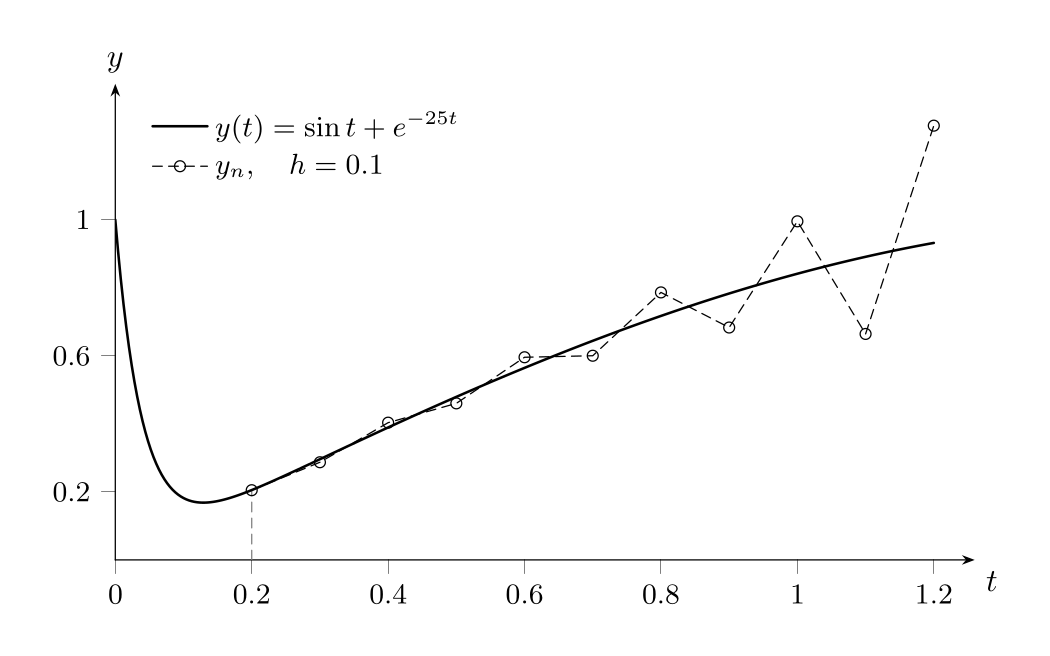

***Figure 1.*** *Exact solution and unstable explicit Euler integration for $h=0.1$*

Now use implicit Euler for the same problem

$$
y_{n+1}=y_n+h(-25y_{n+1}+\cos t_{n+1}+25\sin t_{n+1}).\tag{98}
$$

The step equation is linear in $y_{n+1}$, so we can solve it explicitly

$$
y_{n+1}=\frac{y_n+h(\cos t_{n+1}+25\sin t_{n+1})}{1+25h}.\tag{99}
$$

The amplification factor is $1/(1+25h)$, so perturbations decay for every $h>0$. In the values printed below, the maximum absolute errors for implicit Euler are about $1.8\cdot10^{-3}$ at $h=0.1$ and $4.9\cdot10^{-3}$ at $h=0.3$. The larger step supplies values only at $0.2,0.5,0.8,1.1$ on the displayed grid. The last column is blank at the other times.

In [1]:
import math

def y_exact(t):
    return math.sin(t) + math.exp(-25 * t)

def f(t, y):
    return -25 * y + math.cos(t) + 25 * math.sin(t)

def euler_explicit(t0, y0, h, steps):
    values = [y0]
    for n in range(steps):
        t = t0 + n * h
        values.append(values[-1] + h * f(t, values[-1]))
    return values

def euler_implicit(t0, y0, h, steps):
    values = [y0]
    for n in range(1, steps + 1):
        t = t0 + n * h
        forcing = math.cos(t) + 25 * math.sin(t)
        values.append((values[-1] + h * forcing) / (1 + 25 * h))
    return values

In [2]:
t0, y0 = 0.2, 0.205
explicit_01 = euler_explicit(t0, y0, 0.1, 10)
explicit_0025 = euler_explicit(t0, y0, 0.025, 40)
implicit_01 = euler_implicit(t0, y0, 0.1, 10)
implicit_03 = dict(zip(range(0, 11, 3), euler_implicit(t0, y0, 0.3, 3)))

print(f"{'t':>5} {'y_exact':>12} {'Exp h=0.1':>12} {'Exp h=0.025':>12} {'Imp h=0.1':>12} {'Imp h=0.3':>12}")
for n in range(11):
    t = t0 + 0.1 * n
    coarse = f"{implicit_03[n]:12.6f}" if n in implicit_03 else ""
    print(f"{t:5.2f} {y_exact(t):12.6f} {explicit_01[n]:12.6f} {explicit_0025[4*n]:12.6f} {implicit_01[n]:12.6f} {coarse}")

    t      y_exact    Exp h=0.1  Exp h=0.025    Imp h=0.1    Imp h=0.3
 0.20     0.205407     0.205000     0.205000     0.205000     0.205000
 0.30     0.296073     0.287180     0.295776     0.296953 
 0.40     0.389464     0.403564     0.389601     0.389316 
 0.50     0.479429     0.460306     0.479651     0.478754     0.478114
 0.60     0.564643     0.595864     0.564912     0.563684 
 0.70     0.644218     0.600344     0.644527     0.643061 
 0.80     0.717356     0.786512     0.717703     0.716035     0.713800
 0.90     0.783327     0.683293     0.783708     0.781861 
 1.00     0.841471     0.995539     0.841883     0.839877 
 1.10     0.891207     0.664400     0.891645     0.889501     0.886345
 1.20     0.932039     1.276779     0.932499     0.930239 


Even after the fast component becomes small in the exact solution, its numerical amplification still controls the permissible step for explicit Euler. An implicit method with sufficient damping can use larger steps after the transient. The step must still resolve the required solution accuracy, and for nonlinear problems an implicit step generally requires solving an equation.

## References

1. **E. Hairer, S. P. Nørsett, G. Wanner.** *Solving Ordinary Differential Equations I: Nonstiff Problems.* 2nd revised edition. Springer, 1993. Zero-stability, linear multistep methods, and Runge–Kutta methods.
2. **E. Hairer, G. Wanner.** *Solving Ordinary Differential Equations II: Stiff and Differential-Algebraic Problems.* 2nd revised edition. Springer, 1996. Absolute stability and stiff problems.
3. **A. Iserles.** *A First Course in the Numerical Analysis of Differential Equations.* 2nd edition. Cambridge University Press, 2009. Difference equations and numerical methods for ODEs.